# Retail Customer Segmentation
Revised from Nivedha Sivakumar's saved RFM and K-means capstone.

## Goal and methods
Describe purchasing behavior using recency (days), frequency (distinct invoices), and monetary value (recorded currency units). The two supplied files are transaction partitions, not supervised train/test sets. Combine them for this descriptive snapshot, deduplicate, then cluster log-transformed and standardized RFM features.

Missing customer identifiers are excluded, never replaced by invoice identifiers. Returns, cancellations, zero-price rows, and nonpositive quantities are excluded: the analysis measures positive purchases, not net spend. No revenue uplift, predictive accuracy, or retention claim is made. Cluster numbers are arbitrary.


## Executed results

Analyzed 392,692 retained positive-purchase rows across 4,338 identified customers. Selected k=2 from k=2..6 by sampled silhouette (0.425); agreement across the two tested random seeds was ARI=1.000. This does not establish stability over time or business value. Segment profiles are shown below.

In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11})
SEED = 42


## Load and check the local source partitions
Data is excluded from GitHub. No customer-level previews are printed.

In [2]:
parts = [pd.read_excel(Path('data') / filename, dtype={'InvoiceNo': str, 'CustomerID': str}) for filename in ['train.xlsx', 'test.xlsx']]
required = {'InvoiceNo','Quantity','InvoiceDate','UnitPrice','CustomerID'}
assert all(required.issubset(p.columns) for p in parts), 'Required transaction columns missing'
raw = pd.concat(parts, ignore_index=True)
quality = {'input_rows': len(raw), 'duplicate_rows': int(raw.duplicated().sum())}
df = raw.drop_duplicates().copy()
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
for col in ['Quantity','UnitPrice']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
missing_id = df['CustomerID'].isna() | df['CustomerID'].str.strip().eq('')
invalid = df['InvoiceDate'].isna() | df['InvoiceNo'].isna() | df['Quantity'].isna() | df['UnitPrice'].isna()
canceled = df['InvoiceNo'].str.upper().str.startswith('C', na=False)
nonpositive = df['Quantity'].le(0) | df['UnitPrice'].le(0)
quality.update({'missing_customer_id_rows': int(missing_id.sum()), 'invalid_required_rows': int(invalid.sum()),
                'cancellation_rows': int(canceled.sum()), 'nonpositive_rows': int(nonpositive.sum())})
# Exclusion counts can overlap; the final retained count is computed from their union.
df = df.loc[~(missing_id | invalid | canceled | nonpositive)].copy()
df['Amount'] = df['Quantity'] * df['UnitPrice']
assert np.isfinite(df['Amount']).all()
quality.update({'retained_rows': len(df), 'customers': int(df['CustomerID'].nunique()),
                'start_date': str(df['InvoiceDate'].min().date()), 'end_date': str(df['InvoiceDate'].max().date())})
print(json.dumps(quality, indent=2))


{
  "input_rows": 541909,
  "duplicate_rows": 5268,
  "missing_customer_id_rows": 135037,
  "invalid_required_rows": 0,
  "cancellation_rows": 9251,
  "nonpositive_rows": 11763,
  "retained_rows": 392692,
  "customers": 4338,
  "start_date": "2010-12-01",
  "end_date": "2011-12-09"
}


## Build the customer-level RFM snapshot

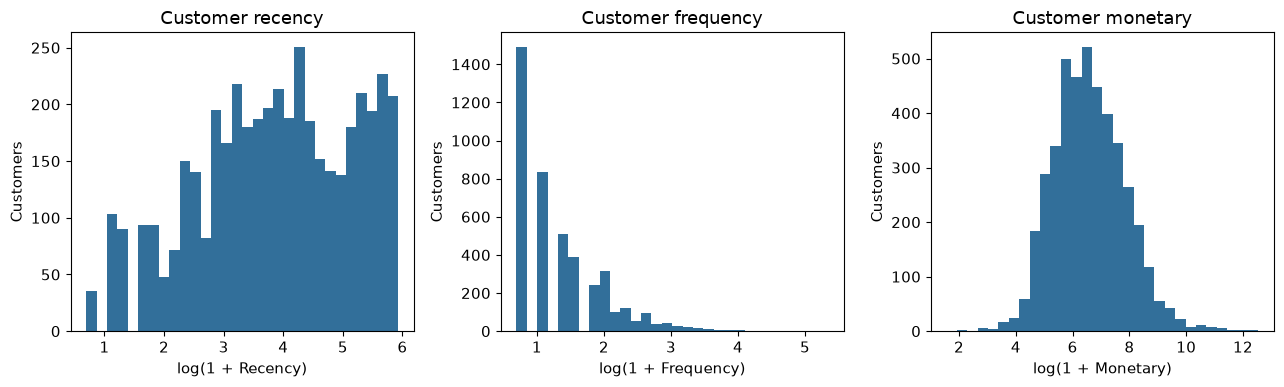

In [3]:
snapshot = df['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
rfm = df.groupby('CustomerID').agg(last_purchase=('InvoiceDate','max'), Frequency=('InvoiceNo','nunique'), Monetary=('Amount','sum'))
rfm['Recency'] = (snapshot - rfm['last_purchase'].dt.normalize()).dt.days
rfm = rfm[['Recency','Frequency','Monetary']]
assert rfm.index.is_unique and (rfm > 0).all().all()
from sklearn.preprocessing import StandardScaler
scaled = StandardScaler().fit_transform(np.log1p(rfm))
assert np.isfinite(scaled).all()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax,col in zip(axes, rfm.columns):
    ax.hist(np.log1p(rfm[col]), bins=30, color='#326f9a')
    ax.set(title=f'Customer {col.lower()}', xlabel=f'log(1 + {col})', ylabel='Customers')
plt.tight_layout(); plt.show()


## Select a cluster count from the descriptive data
Compare k=2 through 6 using a fixed sample for silhouette scoring (at most 2,000 customers). Select the highest sampled silhouette; inspect the elbow and profiles as supporting evidence. This is internal separation, not external business validation.

 k   inertia  silhouette
 2 6476.5069      0.4252
 3 4858.0785      0.3297
 4 3925.2745      0.3302
 5 3269.0748      0.3197
 6 2840.6540      0.3185


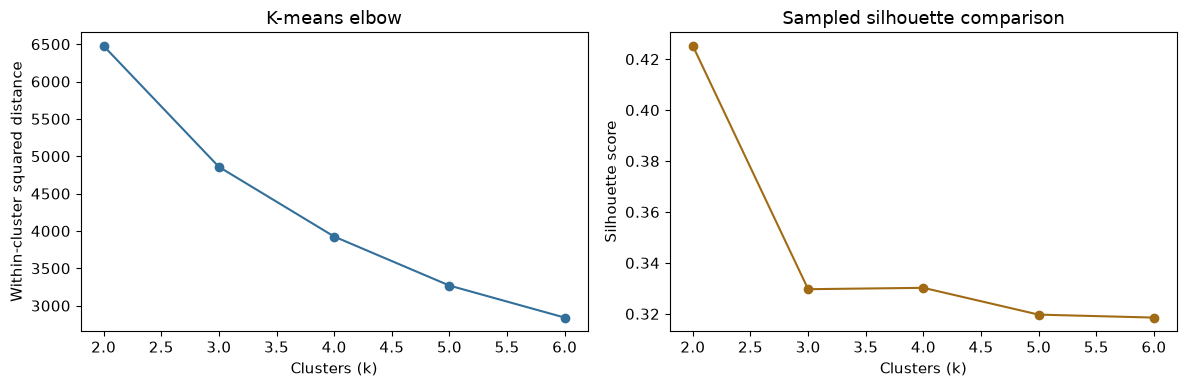

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
rows = []
models = {}
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(scaled)
    models[k] = model
    rows.append({'k':k, 'inertia':float(model.inertia_), 'silhouette':float(silhouette_score(scaled, model.labels_, sample_size=min(2000,len(rfm)), random_state=SEED))})
comparison = pd.DataFrame(rows)
print(comparison.round(4).to_string(index=False))
best_k = int(comparison.loc[comparison['silhouette'].idxmax(), 'k'])
labels = models[best_k].labels_
alternate = KMeans(n_clusters=best_k, n_init=20, random_state=7).fit_predict(scaled)
stability = adjusted_rand_score(labels, alternate)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(comparison['k'], comparison['inertia'], marker='o', color='#326f9a')
axes[0].set(title='K-means elbow', xlabel='Clusters (k)', ylabel='Within-cluster squared distance')
axes[1].plot(comparison['k'], comparison['silhouette'], marker='o', color='#a16b15')
axes[1].set(title='Sampled silhouette comparison', xlabel='Clusters (k)', ylabel='Silhouette score')
plt.tight_layout(); plt.show()


## Interpret aggregate segment profiles
Only customer counts and median RFM are shown. Segment numbers do not imply a ranking.

         Customers  Median_recency_days  Median_invoices  Median_purchase_value
segment                                                                        
0             1668                 17.0              6.0                2058.17
1             2670                 96.0              1.0                 362.01


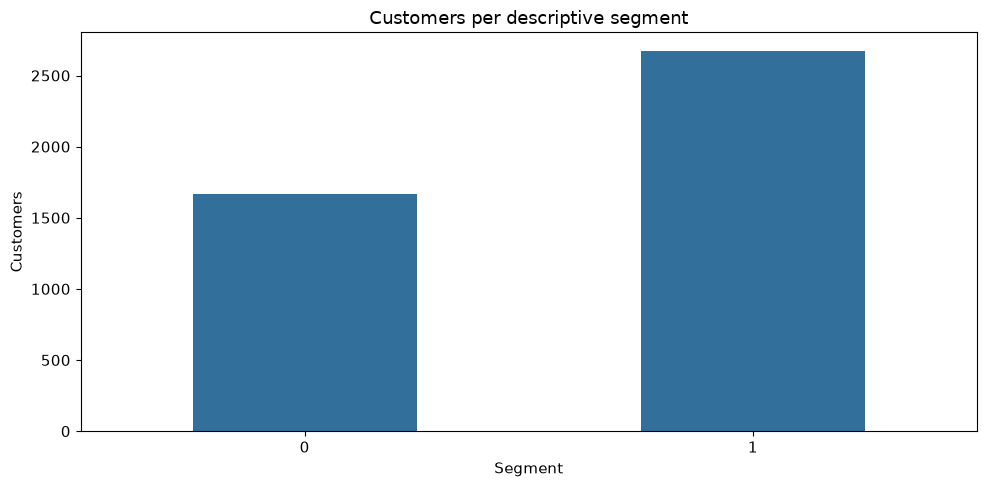

Selected k=2; seed stability adjusted Rand index=1.000


In [5]:
profiles = rfm.assign(segment=labels).groupby('segment').agg(Customers=('Recency','size'), Median_recency_days=('Recency','median'), Median_invoices=('Frequency','median'), Median_purchase_value=('Monetary','median'))
assert profiles['Customers'].sum() == len(rfm)
print(profiles.round(2).to_string())
profiles['Customers'].plot.bar(color='#326f9a', rot=0)
plt.title('Customers per descriptive segment'); plt.xlabel('Segment'); plt.ylabel('Customers')
plt.tight_layout(); plt.show()
results = {'quality':quality, 'snapshot':str(snapshot.date()), 'selected_k':best_k,
           'silhouette':float(comparison.set_index('k').loc[best_k,'silhouette']), 'seed_stability_ARI':float(stability),
           'profiles': profiles.reset_index().to_dict(orient='records')}
Path('results.json').write_text(json.dumps(results, indent=2))
print(f'Selected k={best_k}; seed stability adjusted Rand index={stability:.3f}')


## Limits and next steps
Excluding unidentified customers changes the covered population. Purchase-only monetary value ignores subsequent refunds and cannot be called net revenue. Heavy purchasers and skew can affect K-means even after transformation. Profiles are descriptive associations and need business review and temporal stability checks before targeting. The exact course-split provenance and redistribution rights remain unverified.


Exact duplicate rows are assumed to be duplicate observations; without a transaction-line identifier, legitimate identical line items cannot be distinguished with certainty.